# 🌳 Notebook 4 — Long-Chain Branching (Coordination Polymerization)
| | |
|---|---|
| ⏱ Time | ~20 min |
| 🧭 Type | **steady state Monte Carlo** (book Ch. 3, Case Study 3.3) |
| 🎯 You will learn | keep a **pool** of molecules that can react again · count branches · classify linear / comb / hyperbranched |
| 🧰 Uses | Notebook 2's chain-growth loop + a list of "macromonomers" |
| 📖 Book algorithms | *Coordination Polymerization with LCB Formation* · *… with LCB Topology Classification* |

**The chemistry in one picture:** a catalyst makes a chain. When it ends by **β-hydride elimination**, the dead chain keeps a vinyl end → it becomes a **macromonomer**. A later growing chain can grab that whole macromonomer → a **long-chain branch (LCB)**. See *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture* for the kinetics.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
random.seed(11)
plt.rcParams.update({"figure.figsize": (6, 3.6), "axes.grid": True, "grid.alpha": 0.3})
trapz = getattr(np, "trapezoid", None) or np.trapz

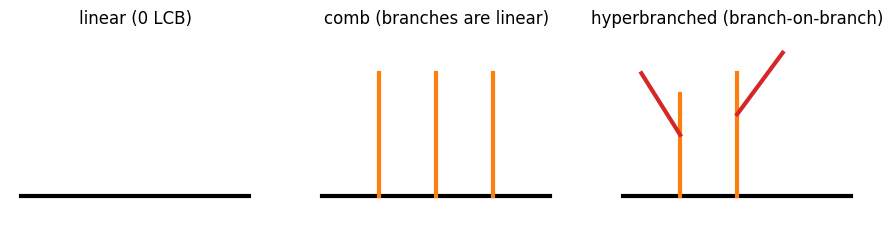

In [2]:
# A cartoon of the three architectures we will count
fig, ax = plt.subplots(1, 3, figsize=(11, 2.4))
def line(a, x0, y0, x1, y1, c="k"): a.plot([x0, x1], [y0, y1], c=c, lw=3)
line(ax[0], 0, 0, 10, 0)
line(ax[1], 0, 0, 10, 0); [line(ax[1], x, 0, x, 3, "tab:orange") for x in (2.5, 5, 7.5)]
line(ax[2], 0, 0, 10, 0); line(ax[2], 5, 0, 5, 3, "tab:orange"); line(ax[2], 5, 2, 7, 3.5, "tab:red")
line(ax[2], 2.5, 0, 2.5, 2.5, "tab:orange"); line(ax[2], 2.5, 1.5, 0.8, 3, "tab:red")
for a, t in zip(ax, ["linear (0 LCB)", "comb (branches are linear)", "hyperbranched (branch-on-branch)"]):
    a.set_title(t); a.axis("off"); a.set_ylim(-0.5, 4)
plt.show()

## 1 · The algorithm
For every new chain:
1. **Grow**: with prob. `P_p` propagate. When propagating, with prob. `P_LCB` the chain adds a *whole macromonomer* (length `m`, with `j` branches of its own) instead of one monomer:
   `n ← n + m`, `branches ← branches + j + 1`
2. **Stop**: decide how — transfer to CTA (prob. `P_CTA`, saturated end → dead) or β-hydride elimination (vinyl end → **joins the macromonomer pool**).

📝 One bookkeeping detail: a macromonomer that gets swallowed is no longer a separate molecule, so we mark it as *consumed* and leave it out of the final distribution.

In [3]:
def simulate_lcb(N, Pp, P_LCB, P_CTA):
    n_arr, b_arr, hb_arr = [], [], []     # length, LCB count, branch-on-branch count
    consumed = []
    pool = []                             # indices of chains that are macromonomers
    for k in range(N):
        n, i, hb = 1, 0, 0
        while random.random() <= Pp:                              # propagation?
            if random.random() <= P_LCB and pool:                 # LCB: grab a macromonomer
                idx = random.randrange(len(pool))
                c = pool[idx]; pool[idx] = pool[-1]; pool.pop()   # fast random removal
                n += n_arr[c];  i += b_arr[c] + 1;  hb += b_arr[c]
                consumed[c] = True
            else:
                n += 1                                            # regular monomer
        if random.random() > P_CTA:                               # β-hydride elimination
            pool.append(k)
        n_arr.append(n); b_arr.append(i); hb_arr.append(hb); consumed.append(False)
    keep = ~np.array(consumed)
    return np.array(n_arr)[keep], np.array(b_arr)[keep], np.array(hb_arr)[keep]

D, B, HB = simulate_lcb(200_000, Pp=0.99, P_LCB=0.005, P_CTA=0.2)
print(f"molecules left: {len(D):,}   average LCB per molecule: {B.mean():.3f}")
print(f"linear: {np.mean(B==0):.1%}   comb: {np.mean((B>0)&(HB==0)):.1%}   hyperbranched: {np.mean(HB>0):.1%}")

molecules left: 100,870   average LCB per molecule: 0.983
linear: 67.0%   comb: 18.9%   hyperbranched: 14.1%


## 2 · Branching broadens the MWD

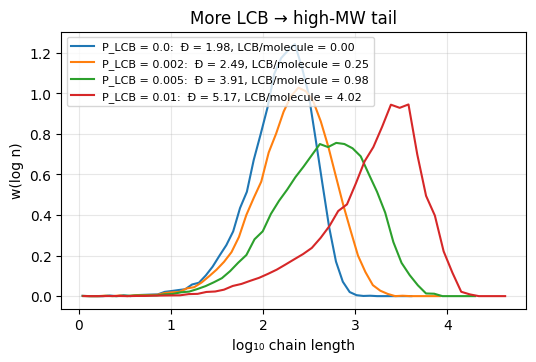

In [4]:
def wlog_hist(D, bins=50):
    edges = np.logspace(0, np.log10(3 * D.max()), bins)     # extend past the longest chain → complete tail
    h, _ = np.histogram(D, bins=edges, weights=D)          # weight by mass
    x = np.log10(np.sqrt(edges[1:]*edges[:-1]))
    y = h / np.diff(np.log10(edges)); y /= trapz(y, x)
    return x, y

for P_LCB in [0.0, 0.002, 0.005, 0.01]:
    D_, B_, _ = simulate_lcb(200_000, 0.99, P_LCB, 0.2)
    PDI = (D_**2).sum() / D_.sum() / D_.mean()
    x, y = wlog_hist(D_)
    plt.plot(x, y, label=f"P_LCB = {P_LCB}:  Đ = {PDI:.2f}, LCB/molecule = {B_.mean():.2f}")
plt.xlabel("log₁₀ chain length"); plt.ylabel("w(log n)"); plt.legend(fontsize=8)
plt.title("More LCB → high-MW tail"); plt.show()

## 3 · Who carries the branches? And what shape are they?
Long molecules are where the branches live — and where the hyperbranched ones appear.

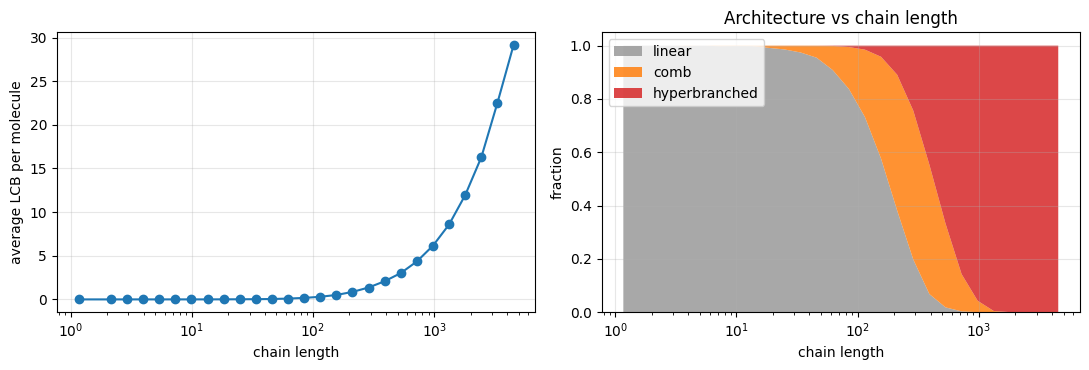

In [5]:
edges = np.logspace(0, np.log10(D.max() + 1), 30)
mid = np.sqrt(edges[1:] * edges[:-1])
which = np.digitize(D, edges) - 1

avgB, lin, comb, hyp = [], [], [], []
for b in range(len(mid)):
    s = which == b
    if s.sum() < 20:                          # skip bins with too few molecules
        avgB.append(np.nan); lin.append(np.nan); comb.append(np.nan); hyp.append(np.nan); continue
    avgB.append(B[s].mean())
    lin.append(np.mean(B[s] == 0)); comb.append(np.mean((B[s] > 0) & (HB[s] == 0))); hyp.append(np.mean(HB[s] > 0))

ok = ~np.isnan(avgB)                       # drop empty bins
mid, avgB, lin, comb, hyp = [np.array(a)[ok] for a in (mid, avgB, lin, comb, hyp)]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(mid, avgB, "o-"); ax[0].set_xlabel("chain length"); ax[0].set_ylabel("average LCB per molecule")
ax[1].stackplot(mid, lin, comb, hyp,
                labels=["linear", "comb", "hyperbranched"], colors=["#999", "tab:orange", "tab:red"], alpha=0.85)
ax[1].set_xscale("log"); ax[1].set_xlabel("chain length"); ax[1].set_ylabel("fraction"); ax[1].legend(loc="upper left")
ax[1].set_title("Architecture vs chain length")
plt.tight_layout(); plt.show()

## ✅ Recap
- A **pool** (a simple Python list) lets molecules made *earlier* react *later*.
- Fast random removal: swap with the last element, then `pop()`.
- Each molecule carries extra labels (`branches`, `branch-on-branch`) → architecture for free.

### 🧪 Try it yourself
1. Set `P_CTA = 1.0` (no β-hydride elimination). What happens to the branching? Why?
2. Which affects Đ more: doubling `P_LCB`, or halving `P_CTA`?
3. Plot the number distribution of branches per molecule (`np.bincount(B)`).

➡️ **Next: Notebook 5 — Step growth & gelation**